<a href="https://colab.research.google.com/github/xploreshivam/cat-and_dog_image_classification/blob/main/Cat_and_Dog_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Project: Cat and Dog Image Classification



In [12]:
import hashlib
import random
import shutil
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
import tensorflow as tf
from tensorflow.keras import layers, models

Configuration & Reproducibility


In [13]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 15
USE_TRANSFER_LEARNING = False  # Set True to switch from Compact CNN to MobileNetV2

BASE_WORK_DIR = Path("./dl003_cats_dogs_workspace")
RAW_EXTRACT_DIR = BASE_WORK_DIR / "raw_download"
SPLIT_DATASET_DIR = BASE_WORK_DIR / "dataset_splits"
OUTPUT_PLOTS_DIR = BASE_WORK_DIR / "outputs"
OUTPUT_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

Download & Inspect Properly Licensed Dataset

In [14]:
def download_dataset() -> Path:
    """
    Downloads the filtered Cats vs. Dogs subset hosted by Google/TensorFlow
    (derived from the Microsoft Research / Kaggle Dogs vs. Cats dataset).
    """
    RAW_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = RAW_EXTRACT_DIR / "cats_and_dogs_filtered.zip"
    extracted_folder = RAW_EXTRACT_DIR / "cats_and_dogs_filtered"

    if not extracted_folder.exists():
        mirror_urls = [
            "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip",
            "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip",
        ]
        for url in mirror_urls:
            try:
                print(f"[INFO] Downloading dataset from {url} ...")
                urllib.request.urlretrieve(url, zip_path)
                break
            except Exception as err:
                print(f"[WARN] Mirror failed ({err}), trying next mirror...")
        print("[INFO] Extracting archive ...")
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(RAW_EXTRACT_DIR)
    else:
        print(f"[INFO] Dataset already exists at: {extracted_folder}")

    return extracted_folder

Verify Images, Prevent Duplicates & Create Train/Val/Test Folders

In [15]:
def compute_file_md5(filepath: Path) -> str:
    """Computes MD5 hash of an image file to prevent duplicate images across splits."""
    hasher = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def is_valid_image(filepath: Path) -> bool:
    """Uses Pillow to verify that an image file is not corrupted or zero-byte."""
    try:
        with Image.open(filepath) as img:
            img.verify()
        return True
    except (UnidentifiedImageError, OSError, SyntaxError):
        return False


def create_clean_splits(
    source_root: Path,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
) -> Path:
    """
    Collects all cat and dog images from the raw dataset, removes corrupt or
    duplicate files via MD5 hashing, and organizes them into strictly disjoint
    train/, validation/, and test/ folders.
    """
    if SPLIT_DATASET_DIR.exists():
        shutil.rmtree(SPLIT_DATASET_DIR)

    classes = ["cats", "dogs"]
    seen_hashes = set()
    duplicates_removed = 0
    corrupt_removed = 0

    for cls_name in classes:
        # Gather candidate files from both original train and validation subdirectories
        candidate_files = []
        for subfolder in ["train", "validation"]:
            cls_dir = source_root / subfolder / cls_name
            if cls_dir.exists():
                candidate_files.extend(sorted(cls_dir.glob("*.*")))

        unique_valid_files = []
        for fpath in candidate_files:
            if not is_valid_image(fpath):
                corrupt_removed += 1
                continue
            file_hash = compute_file_md5(fpath)
            if file_hash in seen_hashes:
                duplicates_removed += 1
                continue
            seen_hashes.add(file_hash)
            unique_valid_files.append(fpath)

        # Shuffle deterministically before splitting
        random.Random(SEED).shuffle(unique_valid_files)
        n_total = len(unique_valid_files)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)

        split_map = {
            "train": unique_valid_files[:n_train],
            "validation": unique_valid_files[n_train : n_train + n_val],
            "test": unique_valid_files[n_train + n_val :],
        }

        for split_name, file_list in split_map.items():
            target_dir = SPLIT_DATASET_DIR / split_name / cls_name
            target_dir.mkdir(parents=True, exist_ok=True)
            for src_file in file_list:
                shutil.copy2(src_file, target_dir / src_file.name)

        print(
            f"[SPLIT] Class '{cls_name}': "
            f"Train={len(split_map['train'])}, "
            f"Val={len(split_map['validation'])}, "
            f"Test={len(split_map['test'])}"
        )

    print(
        f"[CLEANUP] Corrupt images skipped: {corrupt_removed} | "
        f"Duplicate images prevented across splits: {duplicates_removed}"
    )
    return SPLIT_DATASET_DIR


In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load Datasets, Resize Consistently & Configure Augmentation

In [17]:
def load_datasets(split_root: Path):
    """
    Loads train, validation, and test datasets from folders with consistent
    resizing (160x160).
    """
    train_ds = tf.keras.utils.image_dataset_from_directory(
        split_root / "train",
        labels="inferred",
        label_mode="binary",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED,
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        split_root / "validation",
        labels="inferred",
        label_mode="binary",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        split_root / "test",
        labels="inferred",
        label_mode="binary",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    class_names = train_ds.class_names
    print(f"[INFO] Class Mapping: {dict(enumerate(class_names))}")

    # Optimize I/O performance
    autotune = tf.data.AUTOTUNE
    train_ds = train_ds.cache().prefetch(buffer_size=autotune)
    val_ds = val_ds.cache().prefetch(buffer_size=autotune)
    test_ds = test_ds.cache().prefetch(buffer_size=autotune)

    return train_ds, val_ds, test_ds, class_names


Build Model (Compact CNN or Transfer Learning)

In [18]:
def build_model(use_transfer_learning: bool = False) -> tf.keras.Model:
    """
    Builds the binary image classifier.
    - Augmentation layer is active ONLY during training (training=True).
    - Normalization scales pixels to [0, 1].
    """
    data_augmentation = tf.keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.15),
            layers.RandomZoom(0.15),
            layers.RandomContrast(0.10),
        ],
        name="training_only_augmentation",
    )

    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="input_image")
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="pixel_normalization")(x)

    if not use_transfer_learning:
        # Option A: Compact 4-block Convolutional Neural Network
        for filters in [32, 64, 128, 128]:
            x = layers.Conv2D(filters, (3, 3), padding="same", activation="relu")(x)
            x = layers.BatchNormalization()(x)
            x = layers.MaxPooling2D((2, 2))(x)

        x = layers.Flatten()(x)
        x = layers.Dropout(0.5)(x)
        x = layers.Dense(256, activation="relu")(x)
        outputs = layers.Dense(1, activation="sigmoid", name="binary_output")(x)
        model_name = "Compact_CNN_Cat_Dog"
    else:
        # Option B: Transfer Learning with pre-trained MobileNetV2
        base_model = tf.keras.applications.MobileNetV2(
            input_shape=(*IMG_SIZE, 3),
            include_top=False,
            weights="imagenet",
        )
        base_model.trainable = False  # Freeze base weights
        # MobileNetV2 expects [-1, 1], convert from [0, 1]
        x = layers.Rescaling(2.0, offset=-1.0)(x)
        x = base_model(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(1, activation="sigmoid", name="binary_output")(x)
        model_name = "MobileNetV2_Transfer_Cat_Dog"

    model = models.Model(inputs=inputs, outputs=outputs, name=model_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )
    return model

Visualization Helpers: Training Curves, Confusion Matrix & **Predictions**



In [19]:
def plot_training_curves(history: tf.keras.callbacks.History) -> None:
    """Plots and saves Training vs. Validation Accuracy and Loss curves."""
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs_range = range(1, len(acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Accuracy subplot
    axes[0].plot(epochs_range, acc, "o-", label="Training Accuracy", color="#1f77b4")
    axes[0].plot(epochs_range, val_acc, "s--", label="Validation Accuracy", color="#ff7f0e")
    axes[0].set_title("Training vs. Validation Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend(loc="lower right")
    axes[0].grid(True, alpha=0.3)

    # Loss subplot
    axes[1].plot(epochs_range, loss, "o-", label="Training Loss", color="#1f77b4")
    axes[1].plot(epochs_range, val_loss, "s--", label="Validation Loss", color="#ff7f0e")
    axes[1].set_title("Training vs. Validation Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Binary Cross-Entropy Loss")
    axes[1].legend(loc="upper right")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    save_path = OUTPUT_PLOTS_DIR / "training_curves.png"
    plt.savefig(save_path, dpi=150)
    plt.close(fig)
    print(f"[PLOT] Saved learning curves to: {save_path}")


def evaluate_and_plot_confusion_matrix(
    model: tf.keras.Model,
    test_ds: tf.data.Dataset,
    class_names: list[str],
) -> None:
    """
    Evaluates the model on unseen test images and reports Accuracy, Precision,
    Recall, Classification Report, and a Confusion Matrix plot.
    """
    y_true = []
    y_pred_probs = []

    for images, labels in test_ds:
        probs = model.predict(images, verbose=0).flatten()
        y_true.extend(labels.numpy().flatten().astype(int))
        y_pred_probs.extend(probs)

    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred = (y_pred_probs >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print("\n" + "=" * 60)
    print("UNSEEN TEST SET EVALUATION METRICS (DL-003)")
    print("=" * 60)
    print(f"Test Accuracy  : {acc:.4f}")
    print(f"Test Precision : {prec:.4f}")
    print(f"Test Recall    : {rec:.4f}")
    print("\nDetailed Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Plot Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=class_names,
        yticklabels=class_names,
        title="Test Set Confusion Matrix (Cat vs. Dog)",
        ylabel="Actual Label",
        xlabel="Predicted Label",
    )

    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                format(cm[i, j], "d"),
                ha="center",
                va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=12,
                fontweight="bold",
            )

    plt.tight_layout()
    cm_path = OUTPUT_PLOTS_DIR / "confusion_matrix.png"
    plt.savefig(cm_path, dpi=150)
    plt.close(fig)
    print(f"[PLOT] Saved confusion matrix to: {cm_path}")


def plot_sample_predictions(
    model: tf.keras.Model,
    test_ds: tf.data.Dataset,
    class_names: list[str],
    num_samples: int = 12,
) -> None:
    """Displays a 3x4 grid of unseen test images with true vs. predicted labels."""
    all_images = []
    all_labels = []
    for images, labels in test_ds.unbatch().take(num_samples):
        all_images.append(images.numpy().astype("uint8"))
        all_labels.append(int(labels.numpy()[0]))

    batch_tensor = np.array(all_images, dtype="float32")
    probs = model.predict(batch_tensor, verbose=0).flatten()

    fig, axes = plt.subplots(3, 4, figsize=(13, 9))
    for idx, ax in enumerate(axes.flat):
        if idx >= len(all_images):
            ax.axis("off")
            continue
        true_idx = all_labels[idx]
        pred_prob = probs[idx]
        pred_idx = 1 if pred_prob >= 0.5 else 0
        confidence = pred_prob if pred_idx == 1 else (1.0 - pred_prob)

        ax.imshow(all_images[idx])
        is_correct = true_idx == pred_idx
        title_color = "#1b7837" if is_correct else "#d73027"
        ax.set_title(
            f"True: {class_names[true_idx]} | Pred: {class_names[pred_idx]}\n"
            f"Conf: {confidence * 100:.1f}%",
            color=title_color,
            fontsize=9.5,
            fontweight="bold",
        )
        ax.axis("off")

    plt.suptitle("Sample Test Predictions (Green = Correct, Red = Misclassified)", fontsize=13)
    plt.tight_layout()
    pred_path = OUTPUT_PLOTS_DIR / "sample_predictions.png"
    plt.savefig(pred_path, dpi=150)
    plt.close(fig)
    print(f"[PLOT] Saved sample predictions grid to: {pred_path}")

Test Custom Image with Varied Backgrounds

In [20]:
def predict_single_image(
    model: tf.keras.Model,
    image_path: str | Path,
    class_names: list[str],
) -> None:
    """
    Helper to test any custom cat/dog image (e.g., outdoor grass, indoor couch,
    cluttered background) to verify robustness on varied backgrounds.
    """
    img = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    img_array = np.expand_dims(np.array(img, dtype="float32"), axis=0)
    prob = float(model.predict(img_array, verbose=0)[0][0])
    pred_label = class_names[1] if prob >= 0.5 else class_names[0]
    confidence = prob if prob >= 0.5 else (1.0 - prob)
    print(
        f"[CUSTOM TEST] File: {Path(image_path).name} -> "
        f"Predicted: {pred_label} ({confidence * 100:.2f}% confidence)"
    )

Main Execution Pipeline

In [21]:
def main():
    # Step 1: Download & extract properly licensed dataset
    raw_folder = download_dataset()

    # Step 2: Deduplicate (MD5), verify with Pillow, and create Train/Val/Test folders
    split_root = create_clean_splits(raw_folder, train_ratio=0.70, val_ratio=0.15)

    # Step 3: Load datasets with consistent resizing
    train_ds, val_ds, test_ds, class_names = load_datasets(split_root)

    # Step 4: Build model (augmentation inside training pipeline only)
    model = build_model(use_transfer_learning=USE_TRANSFER_LEARNING)
    model.summary()

    # Step 5: Train model with EarlyStopping
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        )
    ]
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
    )

    # Step 6: Plot learning curves
    plot_training_curves(history)

    # Step 7: Evaluate on held-out unseen test set (Precision, Recall, Confusion Matrix)
    evaluate_and_plot_confusion_matrix(model, test_ds, class_names)

    # Step 8: Plot grid of sample test predictions
    plot_sample_predictions(model, test_ds, class_names)

    # Step 9: Save trained model
    model_save_path = OUTPUT_PLOTS_DIR / "cat_dog_classifier.keras"
    model.save(model_save_path)
    print(f"[INFO] Saved trained model to: {model_save_path}")


if __name__ == "__main__":
    main()

[INFO] Dataset already exists at: dl003_cats_dogs_workspace/raw_download/cats_and_dogs_filtered
[SPLIT] Class 'cats': Train=1050, Val=225, Test=225
[SPLIT] Class 'dogs': Train=1050, Val=225, Test=225
[CLEANUP] Corrupt images skipped: 0 | Duplicate images prevented across splits: 0
Found 2100 files belonging to 2 classes.
Found 450 files belonging to 2 classes.
Found 450 files belonging to 2 classes.
[INFO] Class Mapping: {0: 'cats', 1: 'dogs'}


Model: "Compact_CNN_Cat_Dog"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_only_augmentation      │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_normalization (Rescaling) │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,519,553 (13.43 MB)

 Trainable params: 3,518,849 (13.42 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 139ms/step - accuracy: 0.5952 - loss: 0.9999 - precision: 0.6053 - recall: 0.5476 - val_accuracy: 0.5000 - val_loss: 1.1969 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.6495 - loss: 0.6636 - precision: 0.6536 - recall: 0.6362 - val_accuracy: 0.5000 - val_loss: 0.9932 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.6795 - loss: 0.6060 - precision: 0.6794 - recall: 0.6800 - val_accuracy: 0.5000 - val_loss: 0.8966 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.6952 - loss: 0.5801 - precision: 0.6898 - recall: 0.7095 - val_accuracy: 0.5400 - val_loss: 0.6981 - val_precision: 1.0000 - val_recall: 0.0800
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.7019 - loss: 0.5752 - precision: 0.7008 - recall: 0.7048 - val_accuracy: 

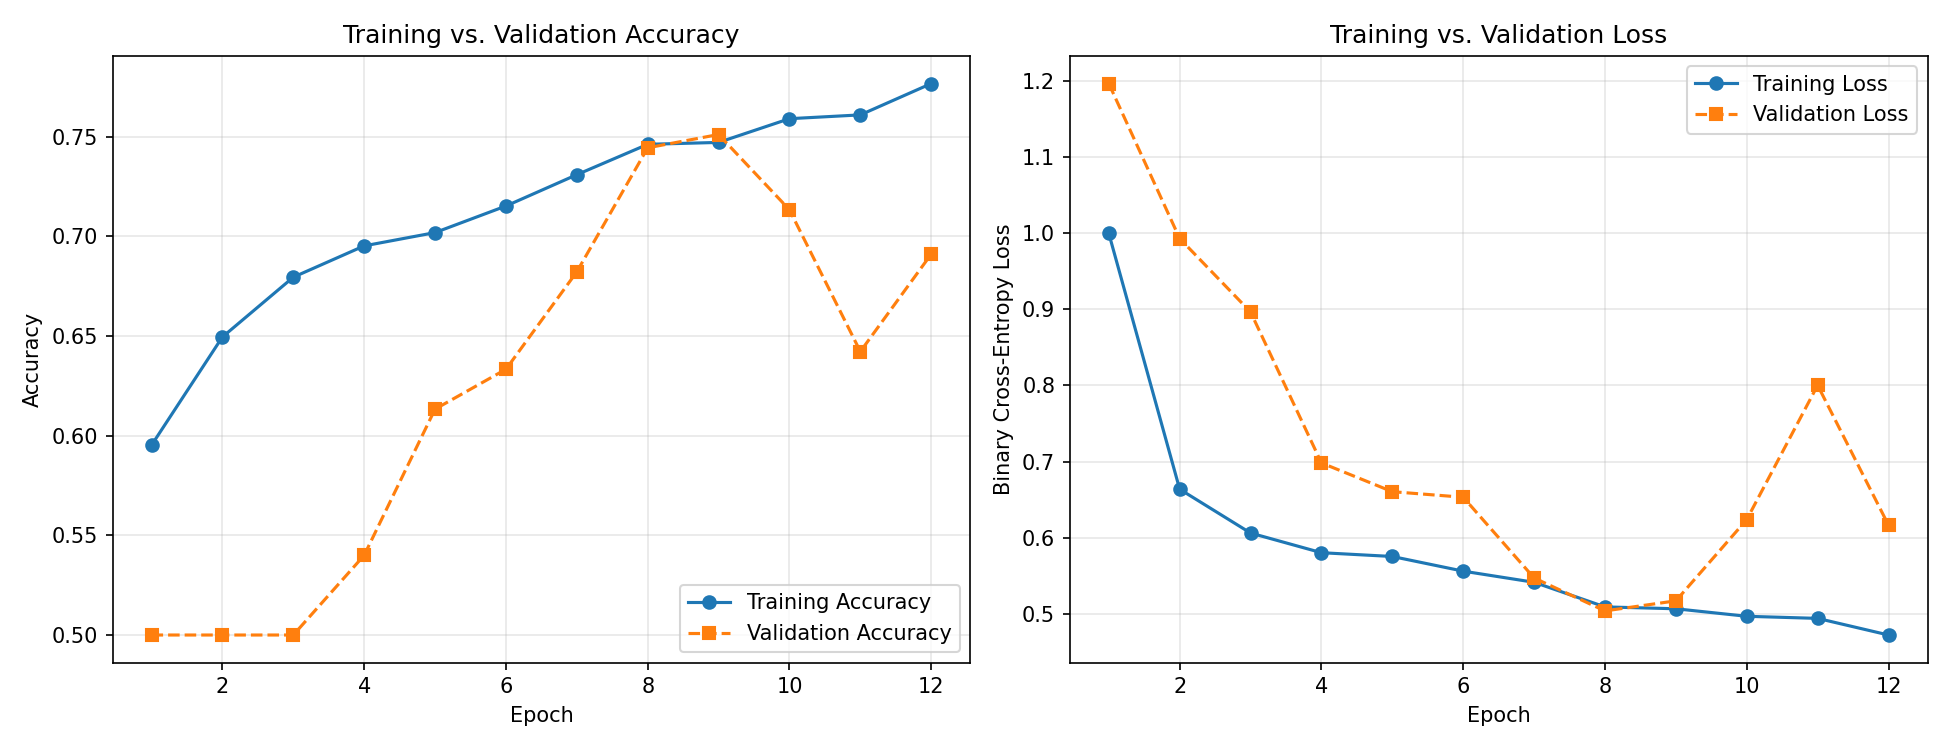

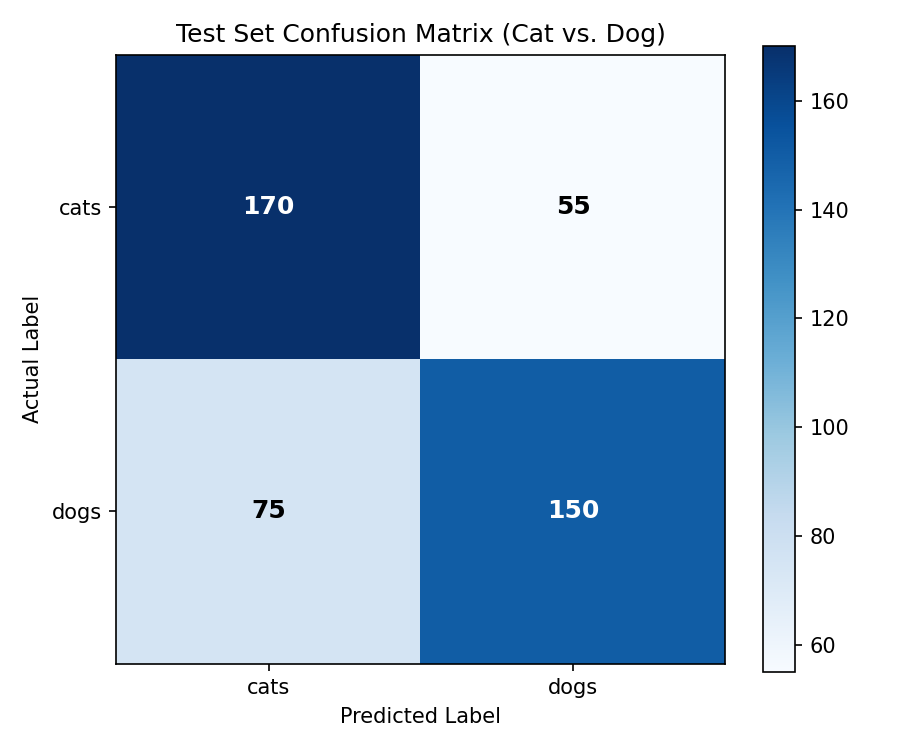

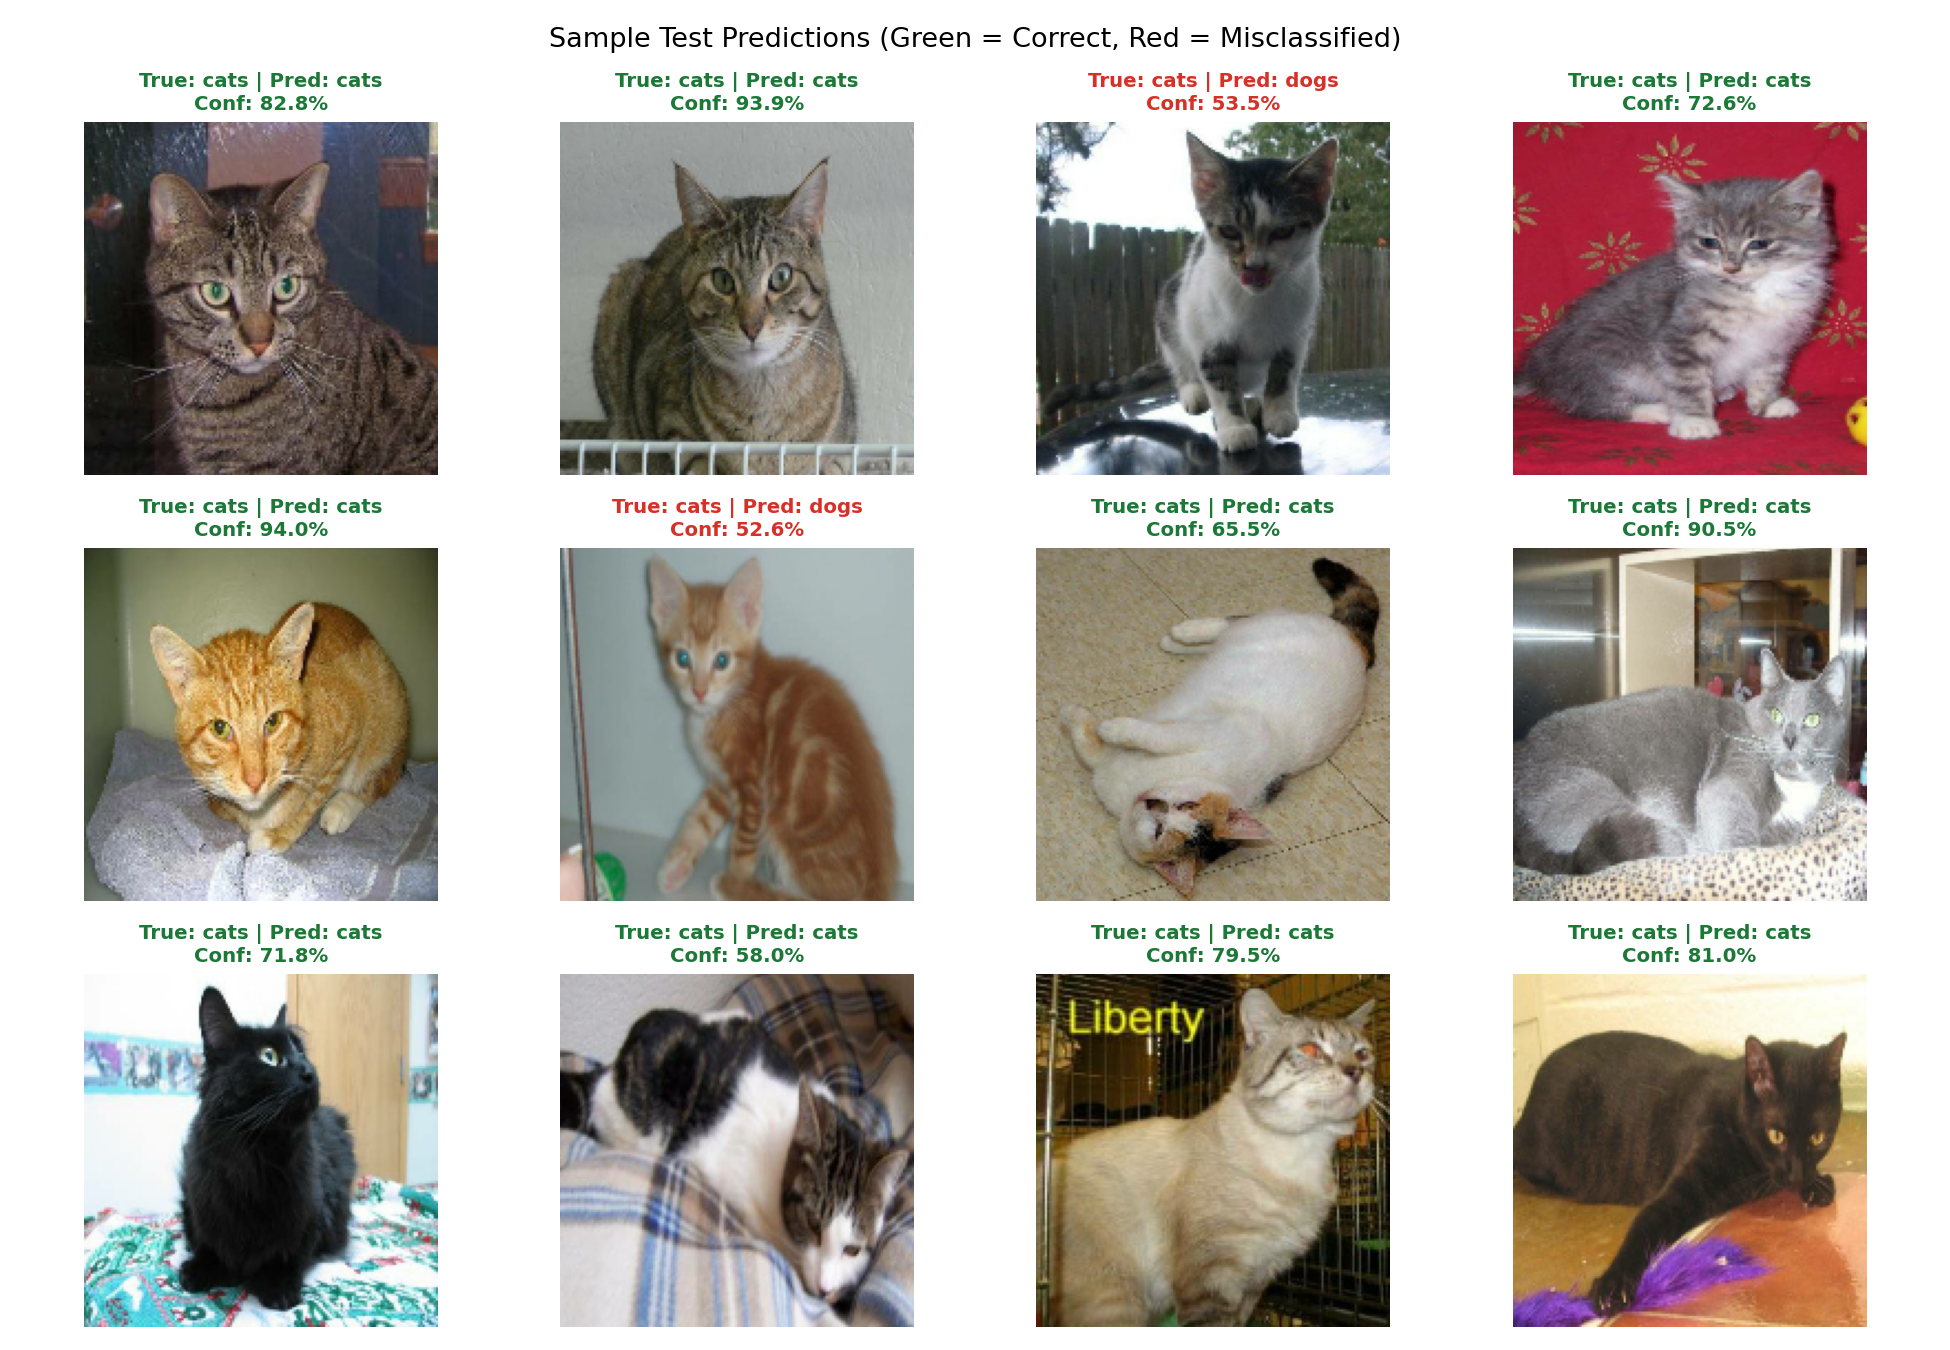

In [22]:
from IPython.display import Image, display
display(Image("dl003_cats_dogs_workspace/outputs/training_curves.png"))
display(Image("dl003_cats_dogs_workspace/outputs/confusion_matrix.png"))
display(Image("dl003_cats_dogs_workspace/outputs/sample_predictions.png"))